In [1]:
import pandas as pd
import random
from datetime import timedelta


# Read data from a JSON file
file_path = 'stoparrivals.json'  # Replace with your actual JSON file path
df = pd.read_json(file_path)

print(df)

# Display updated DataFrame
print(df)

       StopID                             StopName        Lat        Lon  \
0        5313                          TC- Gate 22  43.158464 -77.607674   
1        5308                          TC- Gate 17  43.158195 -77.607727   
2        5304                          TC- Gate 13  43.158163 -77.607895   
3        5311                          TC- Gate 20  43.158453 -77.607756   
4        5301                          TC- Gate 11  43.158147 -77.607973   
...       ...                                  ...        ...        ...   
70881    2853                  Norfolk & Forsythia  43.097953 -77.750103   
70882    1151           E Henrietta & White Spruce  43.103022 -77.615418   
70883    3336             Ridge & 2373 Ridge Petco  43.209037 -77.691473   
70884    5083     Greece Ridge Mall Connection Hub  43.206124 -77.695661   
70885    2575  Monroe Community Coll Main Entrance  43.101842 -77.613798   

       RouteID                 RouteName Direction                   Time  \
0         

In [2]:
import pandas as pd

df 

# Define the correct datetime format
correct_format = '%m/%d/%Y %I:%M:%S %p'

# Function to validate the datetime format
def validate_datetime_format(value):
    try:
        pd.to_datetime(value, format=correct_format)
        return True
    except ValueError:
        return False

# Apply the validation function and filter the DataFrame
df = df[df['Time'].apply(validate_datetime_format)]

print(df)


       StopID                             StopName        Lat        Lon  \
0        5313                          TC- Gate 22  43.158464 -77.607674   
1        5308                          TC- Gate 17  43.158195 -77.607727   
2        5304                          TC- Gate 13  43.158163 -77.607895   
3        5311                          TC- Gate 20  43.158453 -77.607756   
4        5301                          TC- Gate 11  43.158147 -77.607973   
...       ...                                  ...        ...        ...   
70881    2853                  Norfolk & Forsythia  43.097953 -77.750103   
70882    1151           E Henrietta & White Spruce  43.103022 -77.615418   
70883    3336             Ridge & 2373 Ridge Petco  43.209037 -77.691473   
70884    5083     Greece Ridge Mall Connection Hub  43.206124 -77.695661   
70885    2575  Monroe Community Coll Main Entrance  43.101842 -77.613798   

       RouteID                 RouteName Direction                   Time  \
0         

In [3]:
# Assume df is your DataFrame
# Convert 'Time' to datetime
df['Time'] = pd.to_datetime(df['Time'], format='%m/%d/%Y %I:%M:%S %p')

# Generate random offsets between -5 and +5 minutes
random_offsets = [random.randint(-5, 10) for _ in range(len(df))]
df['Actual Arrival Time'] = df['Time'] + pd.to_timedelta(random_offsets, unit='m')

# Display the DataFrame
print(df)

       StopID                             StopName        Lat        Lon  \
0        5313                          TC- Gate 22  43.158464 -77.607674   
1        5308                          TC- Gate 17  43.158195 -77.607727   
2        5304                          TC- Gate 13  43.158163 -77.607895   
3        5311                          TC- Gate 20  43.158453 -77.607756   
4        5301                          TC- Gate 11  43.158147 -77.607973   
...       ...                                  ...        ...        ...   
70881    2853                  Norfolk & Forsythia  43.097953 -77.750103   
70882    1151           E Henrietta & White Spruce  43.103022 -77.615418   
70883    3336             Ridge & 2373 Ridge Petco  43.209037 -77.691473   
70884    5083     Greece Ridge Mall Connection Hub  43.206124 -77.695661   
70885    2575  Monroe Community Coll Main Entrance  43.101842 -77.613798   

       RouteID                 RouteName Direction                Time  \
0           2

Pearson Correlation Matrix:
           StopID       Lat       Lon   RouteID
StopID   1.000000 -0.031981  0.029819 -0.111077
Lat     -0.031981  1.000000  0.057940  0.205879
Lon      0.029819  0.057940  1.000000  0.184253
RouteID -0.111077  0.205879  0.184253  1.000000


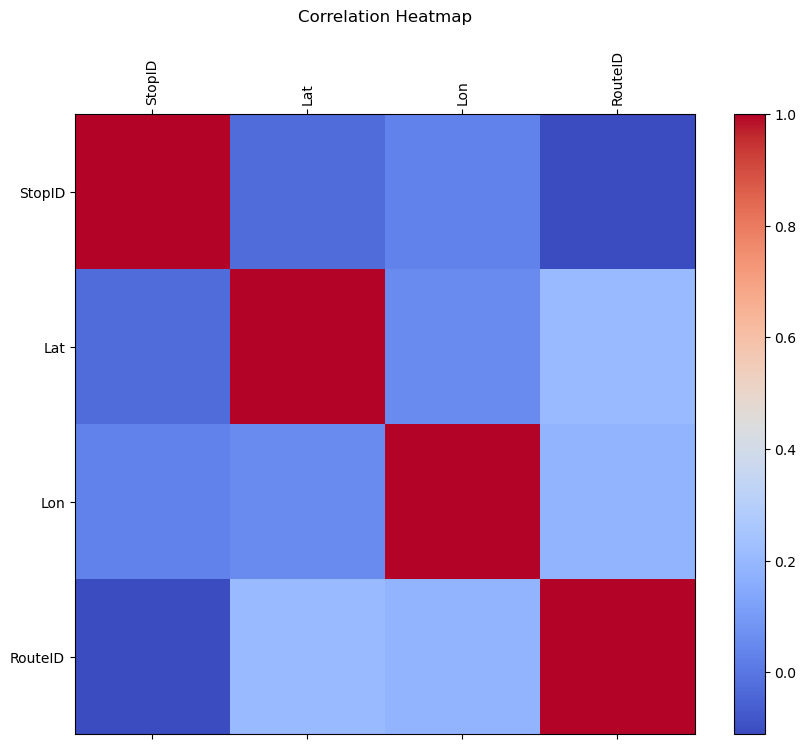

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

# Select only numeric columns for correlation calculation
numeric_df = df.select_dtypes(include=['number'])

# Compute Pearson correlation matrix
correlation_matrix = numeric_df.corr(method='pearson')

# Display the correlation matrix
print("Pearson Correlation Matrix:")
print(correlation_matrix)

# Visualize the correlation matrix using a heatmap
plt.figure(figsize=(10, 8))
plt.matshow(correlation_matrix, cmap='coolwarm', fignum=1)  # Heatmap with coolwarm colormap
plt.colorbar()
plt.xticks(range(len(correlation_matrix.columns)), correlation_matrix.columns, rotation=90)
plt.yticks(range(len(correlation_matrix.columns)), correlation_matrix.columns)
plt.title("Correlation Heatmap", pad=20)
plt.show()


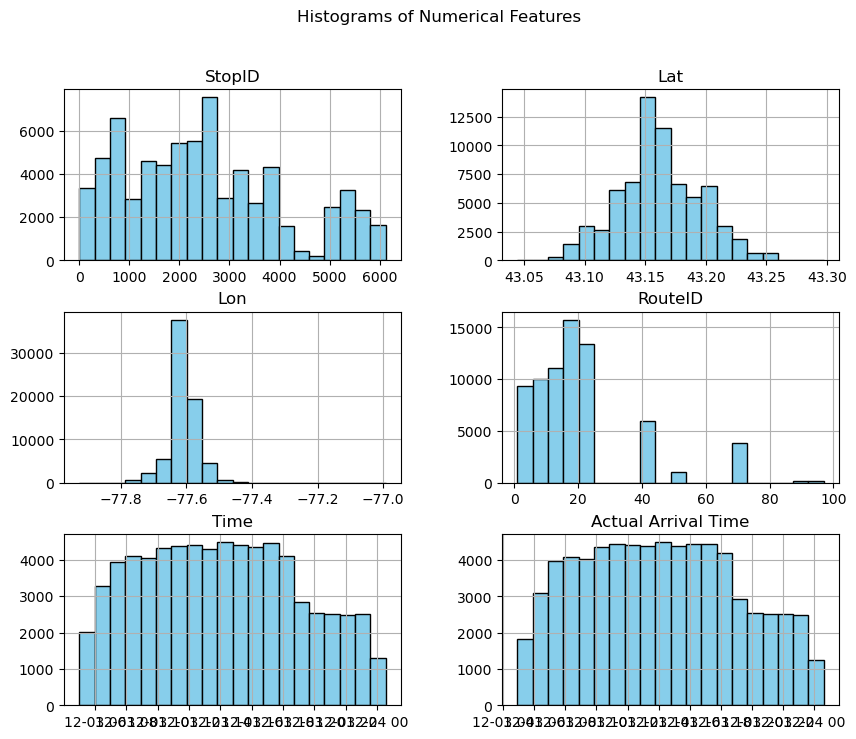

In [5]:
# Plot histograms for numerical attributes
df.hist(bins=20, figsize=(10, 8), color='skyblue', edgecolor='black')
plt.suptitle("Histograms of Numerical Features")
plt.show()


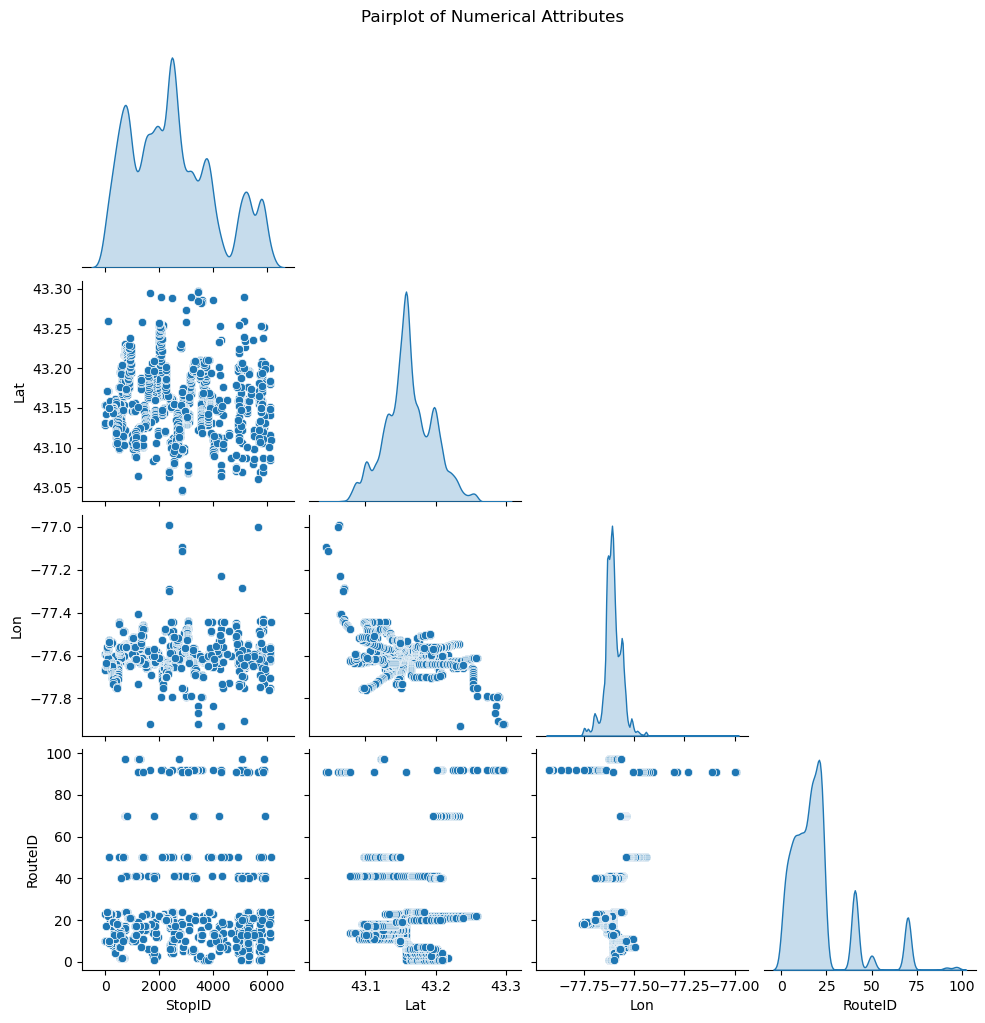

In [6]:
import seaborn as sns

sns.pairplot(df, diag_kind='kde', corner=True)
plt.suptitle("Pairplot of Numerical Attributes", y=1.02)
plt.show()

In [7]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import pickle

# Compute Delay (in seconds)
df['Delay'] = (pd.to_datetime(df['Actual Arrival Time']) - pd.to_datetime(df['Time'])).dt.total_seconds() / 60


# Drop unnecessary columns
columns_to_drop = ['RunDate',  'Destination']
df = df.drop(columns=columns_to_drop)

# Encode categorical columns using Label Encoding
categorical_columns = ['StopName', 'RouteName', 'Direction','Time', 'Actual Arrival Time',]
label_encoders = {}  # Dictionary to store label encoders for future reference

for col in categorical_columns:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le  # Save the encoder for each column

# Save the label encoders
with open("label_encoders.pkl", "wb") as file:
    pickle.dump(label_encoders, file)

# Define features (X) and target (y)
X = df.drop(columns=['Delay'])
y = df['Delay']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Display shapes of training and test sets
print(f"Training features shape: {X_train.shape}")
print(f"Testing features shape: {X_test.shape}")
print(f"Training target shape: {y_train.shape}")
print(f"Testing target shape: {y_test.shape}")


Training features shape: (56708, 9)
Testing features shape: (14178, 9)
Training target shape: (56708,)
Testing target shape: (14178,)


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70886 entries, 0 to 70885
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   StopID               70886 non-null  int64  
 1   StopName             70886 non-null  int32  
 2   Lat                  70886 non-null  float64
 3   Lon                  70886 non-null  float64
 4   RouteID              70886 non-null  int64  
 5   RouteName            70886 non-null  int32  
 6   Direction            70886 non-null  int32  
 7   Time                 70886 non-null  int64  
 8   Actual Arrival Time  70886 non-null  int64  
 9   Delay                70886 non-null  float64
dtypes: float64(3), int32(3), int64(4)
memory usage: 4.6 MB


In [9]:
print(df)

       StopID  StopName        Lat        Lon  RouteID  RouteName  Direction  \
0        5313      1200  43.158464 -77.607674       22         14          2   
1        5308      1195  43.158195 -77.607727       17          8          2   
2        5304      1191  43.158163 -77.607895       18          9          2   
3        5311      1198  43.158453 -77.607756       11          2          2   
4        5301      1189  43.158147 -77.607973       19         10          2   
...       ...       ...        ...        ...      ...        ...        ...   
70881    2853       902  43.097953 -77.750103       18          9          2   
70882    1151       359  43.103022 -77.615418       17          8          2   
70883    3336      1032  43.209037 -77.691473       20         12          2   
70884    5083       519  43.206124 -77.695661       20         12          2   
70885    2575       864  43.101842 -77.613798       17          8          2   

       Time  Actual Arrival Time  Delay


Fold 1
Fold 1 - Mean Absolute Error (MAE): 1.545241665206678
Fold 1 - Mean Squared Error (MSE): 3.671689269028726
Fold 1 - R-squared (R2): 0.8271005653492958

Fold 2
Fold 2 - Mean Absolute Error (MAE): 1.5160124894235631
Fold 2 - Mean Squared Error (MSE): 3.504889418805908
Fold 2 - R-squared (R2): 0.8342787468100469

Fold 3
Fold 3 - Mean Absolute Error (MAE): 1.52766853306574
Fold 3 - Mean Squared Error (MSE): 3.5830538574595323
Fold 3 - R-squared (R2): 0.8290650606240468

Fold 4
Fold 4 - Mean Absolute Error (MAE): 1.5357270625152384
Fold 4 - Mean Squared Error (MSE): 3.6429631717586695
Fold 4 - R-squared (R2): 0.8302875610333103

Fold 5
Fold 5 - Mean Absolute Error (MAE): 1.5219416290860637
Fold 5 - Mean Squared Error (MSE): 3.5246970798651325
Fold 5 - R-squared (R2): 0.8341901615151216

Fold 6
Fold 6 - Mean Absolute Error (MAE): 1.5557674177558267
Fold 6 - Mean Squared Error (MSE): 3.7628186354602726
Fold 6 - R-squared (R2): 0.8207591973531341

Fold 7
Fold 7 - Mean Absolute Error (M

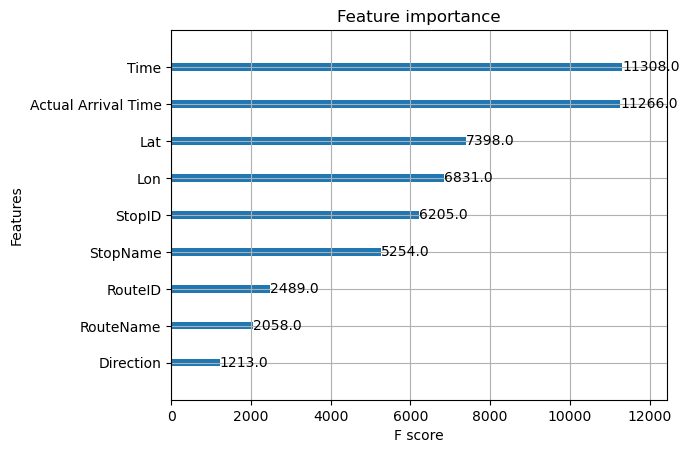

In [10]:
import pandas as pd
from sklearn.model_selection import KFold
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import plot_importance
import matplotlib.pyplot as plt

# Assuming `X` and `y` are preprocessed features and target variable
kf = KFold(n_splits=10, shuffle=True, random_state=42)

# Initialize results storage
fold = 1
mae_list = []
mse_list = []
r2_list = []

for train_index, test_index in kf.split(X):
    print(f"\nFold {fold}")
    
    # Split the data
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]
    
    # Initialize the XGBoost Regressor
    xgb_model = XGBRegressor(
        n_estimators=1000,       # Number of trees
        learning_rate=0.1,       # Learning rate
        max_depth=6,             # Maximum depth of trees
        subsample=0.8,           # Fraction of samples used per tree
        colsample_bytree=0.8,    # Fraction of features used per tree
        gamma=0.8,               # Minimum split gain
        random_state=42          # Seed for reproducibility
    )
    
    # Train the model
    xgb_model.fit(X_train, y_train)
    
    # Make predictions on the test set
    y_pred = xgb_model.predict(X_test)
    
    # Evaluate the model
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    
    # Print results for the current fold
    print(f"Fold {fold} - Mean Absolute Error (MAE): {mae}")
    print(f"Fold {fold} - Mean Squared Error (MSE): {mse}")
    print(f"Fold {fold} - R-squared (R2): {r2}")
    
    # Append metrics to the lists
    mae_list.append(mae)
    mse_list.append(mse)
    r2_list.append(r2)
    
    fold += 1

# Calculate average metrics across all folds
print("\nOverall Performance:")
print(f"Average Mean Absolute Error (MAE): {sum(mae_list) / len(mae_list)}")
print(f"Average Mean Squared Error (MSE): {sum(mse_list) / len(mse_list)}")
print(f"Average R-squared (R2): {sum(r2_list) / len(r2_list)}")

# Optional: Feature importance visualization (based on the last model)
plot_importance(xgb_model)
plt.show()



In [11]:
import pickle

final_model_filename = "xgb_final_model.pkl"
with open(final_model_filename, 'wb') as file:
    pickle.dump(xgb_model, file)

print(f"\nFinal model saved as {final_model_filename}")


Final model saved as xgb_final_model.pkl


In [12]:
# Calculate average delays
actual_avg_delay_seconds = y_test.mean() * 60  # Convert minutes to seconds
predicted_avg_delay_seconds = y_pred.mean() * 60  # Convert minutes to seconds

print(f"Average Actual Delay (seconds): {actual_avg_delay_seconds:.2f}")
print(f"Average Predicted Delay (seconds): {predicted_avg_delay_seconds:.2f}")


Average Actual Delay (seconds): 147.59
Average Predicted Delay (seconds): 149.15


In [13]:
import numpy as np  # Make sure numpy is imported
from sklearn.metrics import mean_absolute_error, mean_squared_error

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
bias = np.mean(y_pred - y_test)

print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"Bias: {bias:.2f}")


Root Mean Squared Error (RMSE): 1.89
Bias: 0.03
